# 03 · Optimización con Optuna y comparación honesta (Producto 2)
En el Producto 1, Random Forest y LightGBM quedaron prácticamente empatados (PR-AUC 0,464 y 0,463). Optimizamos LightGBM con Optuna (métrica: PR-AUC) e incluimos el **tratamiento del desbalance** como una perilla más (`class_weight`). Luego comprobamos **fold a fold** si la mejora es real.

In [1]:
!pip install -q optuna lightgbm

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222, archivo bank-additional-full.csv), copia pública en GitHub.
# Plan B: descarguen bank-additional-full.csv desde UCI y súbanlo al panel Archivos de Colab.
URL = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

NOMBRES = {
    "age": "edad", "job": "ocupacion", "marital": "estado_civil", "education": "educacion",
    "default": "en_mora", "housing": "hipoteca", "loan": "prestamo", "contact": "tipo_contacto",
    "month": "mes", "day_of_week": "dia_semana", "duration": "duracion_llamada",
    "campaign": "contactos_campana", "pdays": "dias_ultimo_contacto", "previous": "contactos_previos",
    "poutcome": "resultado_previo", "emp.var.rate": "tasa_var_empleo", "cons.price.idx": "ipc",
    "cons.conf.idx": "confianza_consumidor", "euribor3m": "euribor3m", "nr.employed": "num_empleados"}

NUMERICAS = ["edad", "contactos_campana", "dias_ultimo_contacto", "contactos_previos",
             "tasa_var_empleo", "ipc", "confianza_consumidor", "euribor3m", "num_empleados"]
CATEGORICAS = ["ocupacion", "estado_civil", "educacion", "en_mora", "hipoteca", "prestamo",
               "tipo_contacto", "mes", "dia_semana", "resultado_previo"]
# duracion_llamada NO entra al modelo: solo se conoce DESPUÉS de la llamada (fuga de datos).

def cargar_datos():
    try:
        df = pd.read_csv(URL, sep=";")
    except Exception:
        df = pd.read_csv("bank-additional-full.csv", sep=";")
    df = df.rename(columns=NOMBRES)
    # 999 significa "nunca fue contactado": no es una cantidad, lo convertimos en faltante
    df["dias_ultimo_contacto"] = df["dias_ultimo_contacto"].replace(999, np.nan)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df.drop(columns="y")

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(41188, 21) | suscriben: 11.3%


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    # add_indicator=True crea la columna "nunca fue contactado" a partir de los 999
    num = Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                    ("escalar", StandardScaler())])
    # "unknown" se mantiene como categoría propia: no saber si tiene mora también informa
    cat = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

In [4]:
import optuna
from lightgbm import LGBMClassifier
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo(trial):
    m = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 64),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 200),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),   # desbalance
        random_state=42, verbose=-1, n_jobs=1)
    return cross_val_score(Pipeline([("prep", preprocesador()), ("modelo", m)]),
                           X_tr, y_tr, cv=cv, scoring="average_precision").mean()

estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo, n_trials=30)
print(f"Mejor PR-AUC (CV): {estudio.best_value:.4f}")
print("Mejores hiperparámetros:", estudio.best_params)

Mejor PR-AUC (CV): 0.4716
Mejores hiperparámetros: {'n_estimators': 425, 'learning_rate': 0.010702212168697748, 'num_leaves': 34, 'min_child_samples': 75, 'subsample': 0.8397986403755999, 'colsample_bytree': 0.7588349336878426, 'reg_lambda': 0.004220408897841884, 'class_weight': None}


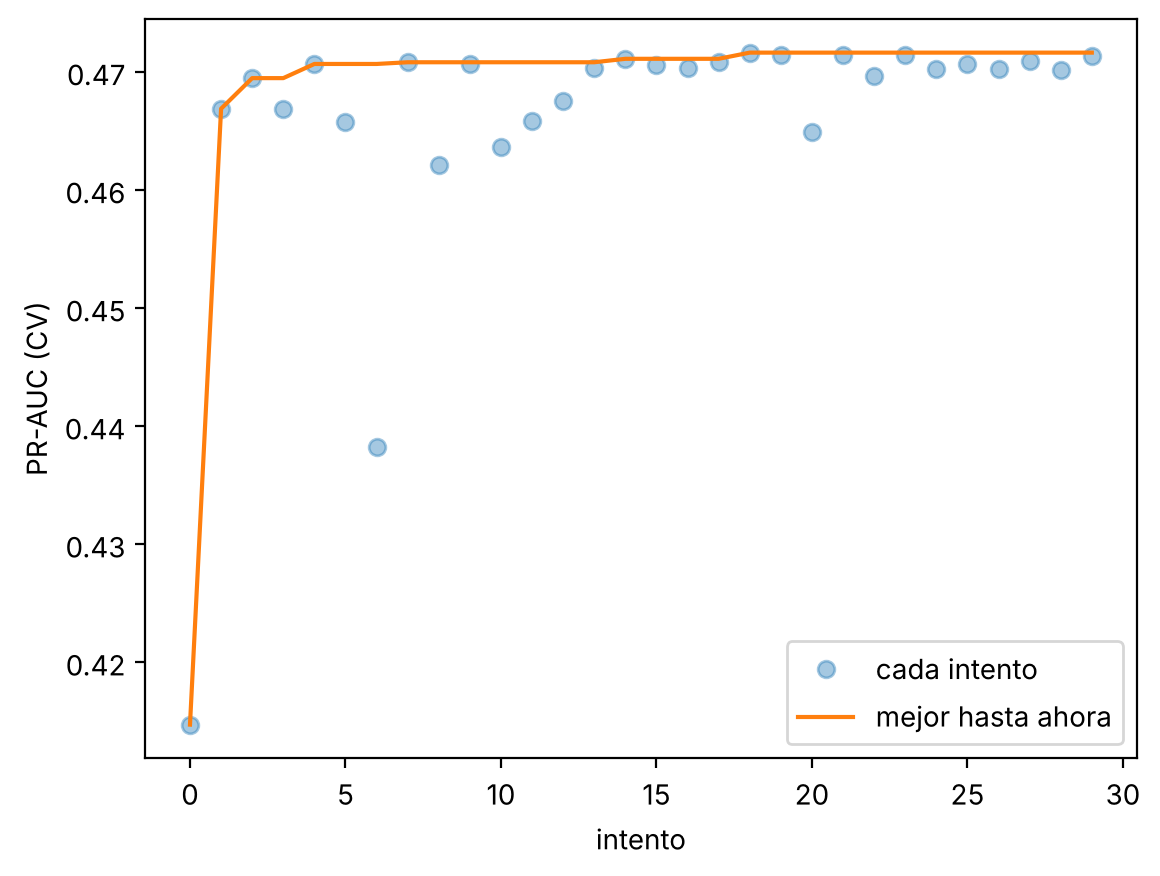

In [5]:
valores = [t.value for t in estudio.trials]
plt.plot(valores, "o", alpha=0.4, label="cada intento")
plt.plot(np.maximum.accumulate(valores), label="mejor hasta ahora")
plt.xlabel("intento"); plt.ylabel("PR-AUC (CV)"); plt.legend(); plt.show()

## ¿La mejora es real? Comparación fold a fold (5 folds × 5 repeticiones)

In [6]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import wilcoxon

cv25 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
modelos = {
    "LightGBM optimizado": LGBMClassifier(**estudio.best_params, subsample_freq=1, random_state=42, verbose=-1, n_jobs=1),
    "LightGBM original": LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1, n_jobs=1),
    "Random Forest (Producto 1)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                       random_state=42, n_jobs=-1),
}
puntajes = {n: cross_val_score(Pipeline([("prep", preprocesador()), ("modelo", m)]), X_tr, y_tr,
                               cv=cv25, scoring="average_precision") for n, m in modelos.items()}
for n, s in puntajes.items():
    print(f"{n:<22} PR-AUC = {s.mean():.4f} ± {s.std():.4f}")
a = puntajes["LightGBM optimizado"]
for n in ["LightGBM original", "Random Forest (Producto 1)"]:
    dif = a - puntajes[n]
    print(f"Optimizado vs. {n}: gana en {(dif > 0).sum()} de {len(dif)} folds · "
          f"diferencia media = {dif.mean():+.4f} · Wilcoxon p = {wilcoxon(dif).pvalue:.2g}")

LightGBM optimizado    PR-AUC = 0.4694 ± 0.0163
LightGBM original      PR-AUC = 0.4625 ± 0.0137
Random Forest (Producto 1) PR-AUC = 0.4632 ± 0.0151
Optimizado vs. LightGBM original: gana en 22 de 25 folds · diferencia media = +0.0070 · Wilcoxon p = 1.1e-06
Optimizado vs. Random Forest (Producto 1): gana en 22 de 25 folds · diferencia media = +0.0062 · Wilcoxon p = 8.2e-06


## Conclusión
- La optimización **sí funciona**: LightGBM optimizado le gana a su versión original en 22 de 25 folds (p < 0,001) y a Random Forest del Producto 1 en 22 de 25 folds (p < 0,001).
- Pero la mejora es **pequeña**: +0,006 a +0,007 de PR-AUC. Es real, no es suerte, pero no cambia el negocio de forma dramática.
- **Decisión:** adoptamos **LightGBM optimizado** como modelo final, porque la mejora es significativa *y* no agrega complejidad frente a Random Forest (es un modelo de tamaño similar y más rápido). Si la diferencia no hubiera sido significativa, nos quedábamos con el modelo del Producto 1.
- **Desbalance:** Optuna eligió `class_weight=None`. Con PR-AUC (una métrica de ordenamiento) no hace falta reponderar; el desbalance se trata eligiendo el **umbral** (ver `05_interpretacion.ipynb`).